# Кластеризация insurance: собственный k-means, sklearn и PCA

Совместная учебная работа. Авторы: **Кирилл Слепцов и Никита Евстигнеев**.

[Исходный публичный Colab](https://colab.research.google.com/drive/1YfAy4jqcFla5DTf3BxSmhb62ZVj3IZZc). Сохранены выполненный код, числовые результаты и график PCA. Новые запуски не выполнялись. Удалены требования сдачи, баллы и неподтверждённое утверждение об улучшении DBSCAN после нормализации.

1338 записей и шесть числовых/закодированных признаков. `region` исключён из признаков и используется только как внешняя разметка для Adjusted Rand Index. Сравниваются собственный k-means, KMeans/AgglomerativeClustering/DBSCAN sklearn; отдельно KMeans после StandardScaler и PCA до двух компонент. Это исследование структуры всего набора без train/test, а не классификатор региона.


## 1. Данные и признаки

`region` имеет четыре значения и используется только при оценке ARI, не при обучении кластеризации.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# Загрузка датасета
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

# [ВЫБОР ПРИЗНАКА]: Выбираем 'region' (4 класса: southwest, southeast, northwest, northeast)
target_column = 'region'
print(f"Целевой признак: {target_column}. Классы: {df[target_column].unique()}")

# Подготовка числовых признаков (нужно 5-10)
# 1-4. age, bmi, children, charges (уже числовые)
# 5-6. Переведем sex и smoker в 0/1, чтобы расширить список признаков
le = LabelEncoder()
df['sex_num'] = le.fit_transform(df['sex'])
df['smoker_num'] = le.fit_transform(df['smoker'])

# Формируем итоговый набор числовых признаков (всего 6)
features = ['age', 'bmi', 'children', 'charges', 'sex_num', 'smoker_num']
X = df[features].copy()
y_true = le.fit_transform(df[target_column]) # Кодируем регионы для сравнения

print(f"Используемые признаки ({len(features)} шт.): {features}")
X.head()

Целевой признак: region. Классы: ['southwest' 'southeast' 'northwest' 'northeast']
Используемые признаки (6 шт.): ['age', 'bmi', 'children', 'charges', 'sex_num', 'smoker_num']


,age,bmi,children,charges,sex_num,smoker_num
0,19,27.900,0,16884.92400,0,1
1,18,33.770,1,1725.55230,1,0
2,28,33.000,3,4449.46200,1,0
3,33,22.705,0,21984.47061,1,0
4,32,28.880,0,3866.85520,1,0


## 2. Собственный k-means

Евклидово расстояние, назначение ближайшему центроиду, пересчёт средних и остановка по сходимости.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

class MyKMeans:
    def __init__(self, n_clusters=4, max_iter=300, tol=1e-4):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.centroids = None
        self.labels_ = None
        self.inertia_ = 0
        self.n_iter_ = 0

    def fit(self, X):
        # Преобразуем входные данные в массив numpy для скорости расчетов
        X_val = X.values if isinstance(X, pd.DataFrame) else X

        np.random.seed(42)
        idx = np.random.choice(len(X_val), self.n_clusters, replace=False)
        self.centroids = X_val[idx]

        for i in range(self.max_iter):
            self.n_iter_ = i + 1

            distances = np.linalg.norm(X_val[:, np.newaxis] - self.centroids, axis=2)
            self.labels_ = np.argmin(distances, axis=1)

            new_centroids = np.array([X_val[self.labels_ == k].mean(axis=0) for k in range(self.n_clusters)])

            if np.all(np.abs(new_centroids - self.centroids) < self.tol):
                break
            self.centroids = new_centroids

        # Расчет инерции (SSE) — сумма квадратов расстояний от точек до их центроидов
        self.inertia_ = 0
        for k in range(self.n_clusters):
            cluster_points = X_val[self.labels_ == k]
            if len(cluster_points) > 0:
                self.inertia_ += np.sum(np.linalg.norm(cluster_points - self.centroids[k], axis=1)**2)

        return self

# --- ЗАПУСК СОБСТВЕННОЙ РЕАЛИЗАЦИИ ---

my_km = MyKMeans(n_clusters=4)
my_km.fit(X)

# Расчет ARI для собственной реализации
# Сравниваем полученные метки (my_km.labels_) с истинными регионами (y_true)
ari_my_kmeans = adjusted_rand_score(y_true, my_km.labels_)

print("=== Результаты собственной реализации K-means ===")
print(f"1. Алгоритм сошелся за {my_km.n_iter_} итераций.")
print(f"2. Инерция (SSE): {my_km.inertia_:.2f}")
print(f"3. Распределение объектов по кластерам: {np.bincount(my_km.labels_)}")
print(f"4. Качество (ARI) относительно регионов: {ari_my_kmeans:.4f}") # <--- ДОБАВЛЕННЫЙ ВЫВОД

# Вывод центроидов для анализа
centroids_df = pd.DataFrame(my_km.centroids, columns=features)
print("\n5. Координаты финальных центроидов:")
display(centroids_df)

=== Результаты собственной реализации K-means ===
1. Алгоритм сошелся за 13 итераций.
2. Инерция (SSE): 12126162656.63
3. Распределение объектов по кластерам: [450 556 155 177]
4. Качество (ARI) относительно регионов: 0.0019

5. Координаты финальных центроидов:


,age,bmi,children,charges,sex_num,smoker_num
0,50.880000,30.858111,1.148889,11242.810962,0.464444,0.046667
1,29.116906,30.080108,1.001799,4182.484750,0.501799,0.000000
2,39.548387,35.045000,1.135484,41224.580772,0.632258,0.967742
3,40.926554,28.163616,1.214689,22493.155465,0.508475,0.581921


## 3. Сравнение с библиотечными алгоритмами


In [ ]:
# Функция для оценки качества (сравнение кластеров с регионами)
def check_quality(name, labels_pred):
    score = adjusted_rand_score(y_true, labels_pred)
    print(f"{name} | ARI Score: {score:.4f}")

# [K-means из библиотеки] - 1 балл
sk_km = KMeans(n_clusters=4, random_state=42, n_init='auto').fit(X)

# [Иерархическая кластеризация] - 1 балл
hier = AgglomerativeClustering(n_clusters=4).fit(X)

# [DBSCAN] - 1 балл
# Для сырых данных charges (до 60000) нужны большие радиусы (eps)
dbscan = DBSCAN(eps=500, min_samples=5).fit(X)

print("Результаты на сырых данных:")
check_quality("Собственный K-means", my_km.labels_)
check_quality("Sklearn K-means", sk_km.labels_)
check_quality("Иерархический (Agglomerative)", hier.labels_)
check_quality("DBSCAN", dbscan.labels_)

Результаты на сырых данных:
Собственный K-means | ARI Score: 0.0019
Sklearn K-means | ARI Score: 0.0019
Иерархический (Agglomerative) | ARI Score: 0.0027
DBSCAN | ARI Score: -0.0013


## 4. StandardScaler и PCA

Сравнение k-means на стандартизованных данных после PCA до двух компонент.



--- После предобработки (Scaling + PCA) ---
K-means + PCA + Scaling | ARI Score: 0.0025


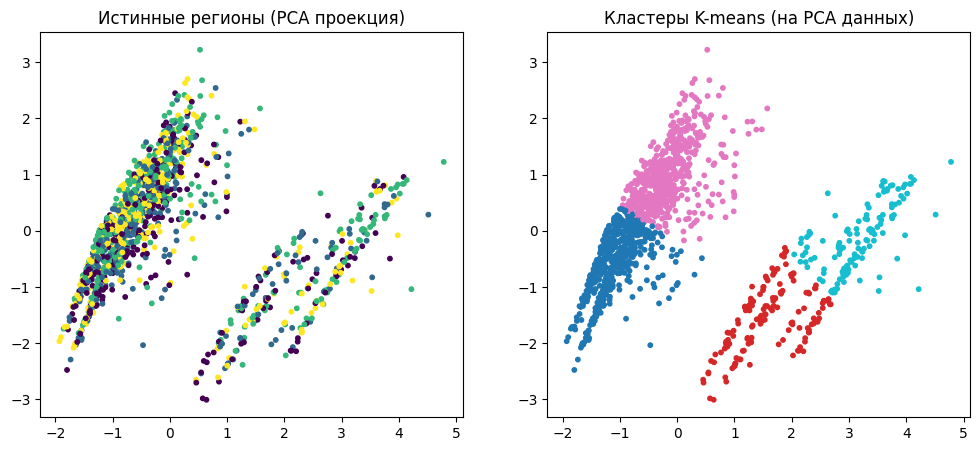

In [ ]:
# [НОРМАЛИЗАЦИЯ] - 1 балл
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# [PCA (Уменьшение размерности)] - 1 балл
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\n--- После предобработки (Scaling + PCA) ---")

# Повторим K-means на обработанных данных
sk_km_pca = KMeans(n_clusters=4, random_state=42, n_init='auto').fit(X_pca)
check_quality("K-means + PCA + Scaling", sk_km_pca.labels_)

# Визуализация результатов
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='viridis', s=10)
plt.title("Истинные регионы (PCA проекция)")

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=sk_km_pca.labels_, cmap='tab10', s=10)
plt.title("Кластеры K-means (на PCA данных)")
plt.show()

## 5. Выводы и ограничения

Сохранённый ARI относительно регионов: собственный k-means 0,0019, sklearn KMeans 0,0019, AgglomerativeClustering 0,0027, DBSCAN −0,0013. KMeans после StandardScaler + PCA: 0,0025. Значения близки к нулю: полученные разбиения почти не соответствуют разметке `region`. Это содержательный отрицательный результат выбранного эксперимента, а не высокая точность модели.

Сырые признаки имеют разные масштабы, и `charges` доминирует в евклидовом расстоянии. PCA здесь одновременно уменьшает размерность и даёт визуализацию; эффект масштабирования отдельно от PCA не изолирован. DBSCAN после масштабирования в сохранённом коде не запускался, поэтому утверждать улучшение нельзя.

Собственный k-means — учебная реализация с одной фиксированной инициализацией, без обработки пустых кластеров и без отдельной проверки на других seed. Ни ARI около нуля, ни двумерная проекция не доказывают равномерность распределения признаков по регионам или отсутствие любой другой структуры.
